# Camada Gold: Perguntas de Negócio

Fase 3 da pipeline (Arquitetura Medallion): a partir da camada **Silver**
(dados já limpos e tipados), este notebook responde às perguntas de negócio
do projeto com consultas SQL, tabelas e gráficos, e constrói uma camada
**Gold** agregada (tabela + view) via `JOIN` + `GROUP BY`.

Dois padrões se repetem nas células abaixo:
* Toda consulta roda com `pd.read_sql(sql, conexao)` e a tabela aparece
  sozinha porque o nome do DataFrame é a última linha da célula, e é assim
  que o Jupyter decide o que mostrar como resultado.
* Todo gráfico segue a mesma receita: cria a figura (`plt.subplots`), desenha
  os dados (`ax.bar`/`ax.barh`), nomeia eixos/título e chama `plt.show()`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from banco import conectar, executar

conexao = conectar()
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Os 5 órgãos com maior custo total

In [2]:
sql_top_orgaos = """
SELECT nome_orgao_superior, ROUND(SUM(valor_total), 2) AS custo_total
FROM silver_viagem
GROUP BY nome_orgao_superior
ORDER BY custo_total DESC
LIMIT 5;
"""
top_orgaos = pd.read_sql(sql_top_orgaos, conexao)
top_orgaos

C:\Users\luana\AppData\Local\Temp\ipykernel_23624\1928753068.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top_orgaos = pd.read_sql(sql_top_orgaos, conexao)


,nome_orgao_superior,custo_total
0,Ministério da Justiça e Segurança Pública,"486,933,121.65"
1,Ministério da Defesa,"156,070,304.49"
2,Ministério da Educação,"111,291,349.34"
3,Ministério do Meio Ambiente e Mudança do Clima,"49,697,710.16"
4,Ministério da Previdência Social,"40,417,309.06"


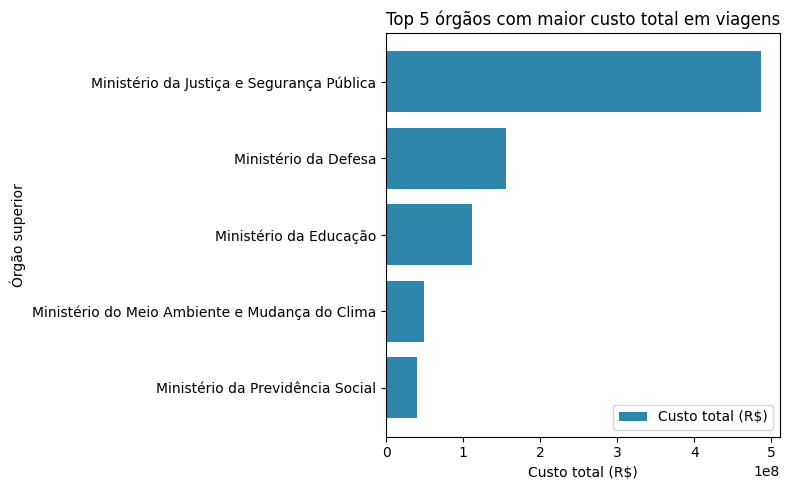

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_orgaos["nome_orgao_superior"], top_orgaos["custo_total"], color="#2E86AB", label="Custo total (R$)")
ax.set_xlabel("Custo total (R$)")
ax.set_ylabel("Órgão superior")
ax.set_title("Top 5 órgãos com maior custo total em viagens")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()


## 2. Os 3 destinos (cidades) com maior custo médio por viagem

O campo `destinos` de `silver_viagem` é texto livre com o itinerário inteiro
da viagem, no formato `Cidade/UF, Cidade/UF, ...` (repete cidades conforme o
número de trechos/diárias). Usar cada linha de `silver_trecho` como um
destino conta a mesma viagem uma vez por trecho e mistura paradas
intermediárias com o destino final. Por isso a consulta extrai, para cada
viagem, a **última cidade da lista em `destinos`** (via
`regexp_split_to_array` por vírgula, pegando o último elemento e separando
cidade/UF pela última `/`) como o destino final, uma linha por viagem, não
por trecho, com um piso de 30 viagens por cidade, alto o suficiente para
não deixar uma rota rara e cara dominar o ranking. Linhas sem destino
identificável (ex.: `destinos = 'Informações protegidas por sigilo'`) são
descartadas por não terem cidade para extrair. Alguns destinos finais são
internacionais (ex.: Xangai/China); isso é esperado, já que viagens
internacionais tendem a custar mais pelo deslocamento aéreo.

In [4]:
sql_top_destinos = r"""
WITH ultimo_destino AS (
    SELECT
        id_viagem,
        valor_total,
        TRIM(SUBSTRING(dest FROM '^(.*)/[^/]+$')) AS destino_cidade,
        TRIM(SUBSTRING(dest FROM '([^/]+)$')) AS destino_uf
    FROM (
        SELECT id_viagem, valor_total,
               (regexp_split_to_array(destinos, '\s*,\s*'))[
                   array_length(regexp_split_to_array(destinos, '\s*,\s*'), 1)
               ] AS dest
        FROM silver_viagem
    ) sub
)
SELECT destino_cidade, destino_uf,
       COUNT(*) AS qtd_viagens,
       ROUND(AVG(valor_total), 2) AS custo_medio
FROM ultimo_destino
WHERE destino_cidade IS NOT NULL AND destino_cidade <> ''
GROUP BY destino_cidade, destino_uf
HAVING COUNT(*) >= 30
ORDER BY custo_medio DESC
LIMIT 3;
"""
top_destinos = pd.read_sql(sql_top_destinos, conexao)
top_destinos

C:\Users\luana\AppData\Local\Temp\ipykernel_23624\1667643103.py:26: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top_destinos = pd.read_sql(sql_top_destinos, conexao)


,destino_cidade,destino_uf,qtd_viagens,custo_medio
0,Amarante do Maranhão,MA,45,"37,661.32"
1,Nonoai,RS,49,"37,060.93"
2,Xangai,China,71,"36,908.84"


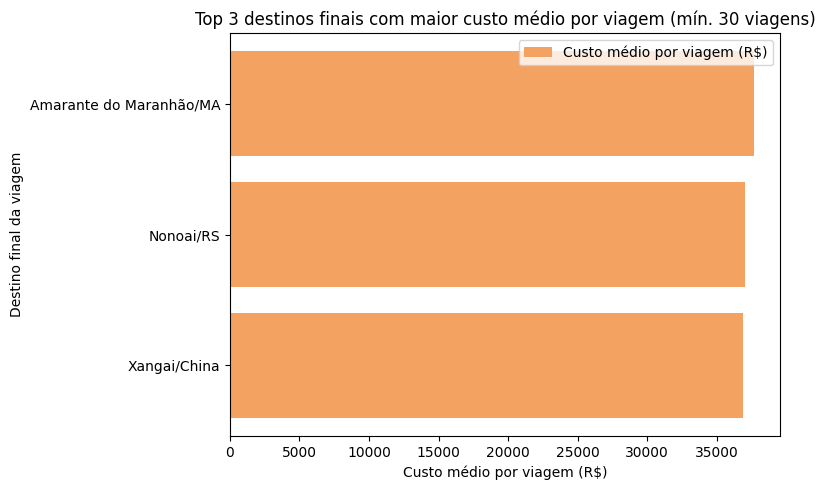

In [5]:
top_destinos["rotulo"] = top_destinos["destino_cidade"] + "/" + top_destinos["destino_uf"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_destinos["rotulo"], top_destinos["custo_medio"], color="#F4A261", label="Custo médio por viagem (R$)")
ax.set_xlabel("Custo médio por viagem (R$)")
ax.set_ylabel("Destino final da viagem")
ax.set_title("Top 3 destinos finais com maior custo médio por viagem (mín. 30 viagens)")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()

## 3. A viagem de maior duração e seu custo total

In [6]:
sql_maior_duracao = """
SELECT id_viagem, nome_viajante, nome_orgao_superior, destinos,
       data_inicio, data_fim, duracao_dias, valor_total
FROM silver_viagem
ORDER BY duracao_dias DESC NULLS LAST
LIMIT 1;
"""
maior_duracao = pd.read_sql(sql_maior_duracao, conexao)
maior_duracao

C:\Users\luana\AppData\Local\Temp\ipykernel_23624\1949462493.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  maior_duracao = pd.read_sql(sql_maior_duracao, conexao)


,id_viagem,nome_viajante,nome_orgao_superior,destinos,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,LUISANGELA CORREA FRANCO DE FARIA,Ministério da Previdência Social,Mogi Mirim/SP,2025-01-13,2026-01-31,384,0.00


C:\Users\luana\AppData\Local\Temp\ipykernel_23624\3034024507.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  media_duracao = pd.read_sql(


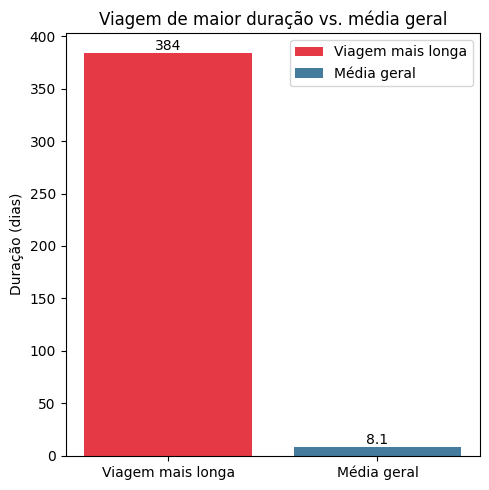

In [7]:
media_duracao = pd.read_sql(
    "SELECT AVG(duracao_dias) AS media FROM silver_viagem;", conexao
)["media"][0]

rotulos = ["Viagem mais longa", "Média geral"]
valores = [maior_duracao["duracao_dias"][0], round(media_duracao, 1)]
cores = ["#E63946", "#457B9D"]

fig, ax = plt.subplots(figsize=(5, 5))
for rotulo, valor, cor in zip(rotulos, valores, cores):
    ax.bar(rotulo, valor, color=cor, label=rotulo)
ax.set_ylabel("Duração (dias)")
ax.set_title("Viagem de maior duração vs. média geral")
for i, v in enumerate(valores):
    ax.text(i, v, str(v), ha="center", va="bottom")
ax.legend()
plt.tight_layout()
plt.show()


## Camada Gold agregada (tabela + view)

Quatro agregações Gold, cada uma criada tanto como **tabela** quanto como
**view**, para que as perguntas 4 a 7 (a seguir) consultem a Gold em vez
da Silver diretamente. Todas fazem `JOIN` com `silver_viagem` para manter
apenas viagens com `situacao = 'Realizada'` (descarta viagens não
realizadas, que não geram custo efetivo) e depois agrupam com `GROUP BY`:

* `gold_gastos_por_orgao` / `vw_gold_gastos_por_orgao`: `JOIN` de
  `silver_pagamento` com `silver_viagem` (filtro de viagem realizada) e
  `GROUP BY` por `nome_orgao_pagador` (o órgão que efetivamente pagou,
  segundo a tabela de pagamentos, usada na pergunta 4). Não agrupa por
  `nome_orgao_superior` de `silver_viagem`: esse campo é o órgão a que a
  viagem pertence, não necessariamente quem pagou a conta.
* `gold_pagamento_por_tipo` / `vw_gold_pagamento_por_tipo`: `JOIN` de
  `silver_pagamento` com `silver_viagem` (mesmo filtro) e `GROUP BY` por
  tipo de pagamento (usada na pergunta 5).
* `gold_trecho_por_transporte` / `vw_gold_trecho_por_transporte`: `JOIN`
  de `silver_trecho` com `silver_viagem` (mesmo filtro) e `GROUP BY` por
  meio de transporte (usada na pergunta 6).
* `gold_trecho_por_uf` / `vw_gold_trecho_por_uf`: `JOIN` de
  `silver_trecho` com `silver_viagem` (mesmo filtro) e `GROUP BY` por UF
  de destino (usada na pergunta 7).

As duas últimas são separadas (em vez de uma só agrupando pelas duas
colunas) porque `destino_uf` e `meio_transporte` têm nulos em linhas
diferentes: agrupar pelas duas ao mesmo tempo descartaria, por exemplo,
trechos com transporte conhecido mas destino vazio, sub-contando a
pergunta 6.

In [8]:
sql_gold = """
DROP TABLE IF EXISTS gold_gastos_por_orgao;
CREATE TABLE gold_gastos_por_orgao AS
SELECT
    p.nome_orgao_pagador,
    COUNT(DISTINCT p.id_viagem) AS qtd_viagens,
    ROUND(SUM(p.valor), 2) AS valor_total_pago,
    ROUND(AVG(p.valor), 2) AS valor_medio_pago
FROM silver_pagamento p
JOIN silver_viagem v ON v.id_viagem = p.id_viagem
WHERE v.situacao = 'Realizada'
GROUP BY p.nome_orgao_pagador;

DROP VIEW IF EXISTS vw_gold_gastos_por_orgao;
CREATE VIEW vw_gold_gastos_por_orgao AS
SELECT
    p.nome_orgao_pagador,
    COUNT(DISTINCT p.id_viagem) AS qtd_viagens,
    ROUND(SUM(p.valor), 2) AS valor_total_pago,
    ROUND(AVG(p.valor), 2) AS valor_medio_pago
FROM silver_pagamento p
JOIN silver_viagem v ON v.id_viagem = p.id_viagem
WHERE v.situacao = 'Realizada'
GROUP BY p.nome_orgao_pagador;

DROP TABLE IF EXISTS gold_pagamento_por_tipo;
CREATE TABLE gold_pagamento_por_tipo AS
SELECT
    p.tipo_pagamento,
    COUNT(*) AS qtd,
    ROUND(SUM(p.valor), 2) AS valor_total,
    ROUND(AVG(p.valor), 2) AS valor_medio
FROM silver_pagamento p
JOIN silver_viagem v ON v.id_viagem = p.id_viagem
WHERE v.situacao = 'Realizada'
GROUP BY p.tipo_pagamento;

DROP VIEW IF EXISTS vw_gold_pagamento_por_tipo;
CREATE VIEW vw_gold_pagamento_por_tipo AS
SELECT
    p.tipo_pagamento,
    COUNT(*) AS qtd,
    ROUND(SUM(p.valor), 2) AS valor_total,
    ROUND(AVG(p.valor), 2) AS valor_medio
FROM silver_pagamento p
JOIN silver_viagem v ON v.id_viagem = p.id_viagem
WHERE v.situacao = 'Realizada'
GROUP BY p.tipo_pagamento;

DROP TABLE IF EXISTS gold_trecho_por_transporte;
CREATE TABLE gold_trecho_por_transporte AS
SELECT t.meio_transporte, COUNT(*) AS qtd_trechos
FROM silver_trecho t
JOIN silver_viagem v ON v.id_viagem = t.id_viagem
WHERE v.situacao = 'Realizada'
  AND t.meio_transporte IS NOT NULL AND t.meio_transporte <> ''
GROUP BY t.meio_transporte;

DROP VIEW IF EXISTS vw_gold_trecho_por_transporte;
CREATE VIEW vw_gold_trecho_por_transporte AS
SELECT t.meio_transporte, COUNT(*) AS qtd_trechos
FROM silver_trecho t
JOIN silver_viagem v ON v.id_viagem = t.id_viagem
WHERE v.situacao = 'Realizada'
  AND t.meio_transporte IS NOT NULL AND t.meio_transporte <> ''
GROUP BY t.meio_transporte;

DROP TABLE IF EXISTS gold_trecho_por_uf;
CREATE TABLE gold_trecho_por_uf AS
SELECT t.destino_uf, COUNT(*) AS qtd_trechos
FROM silver_trecho t
JOIN silver_viagem v ON v.id_viagem = t.id_viagem
WHERE v.situacao = 'Realizada'
  AND t.destino_uf IS NOT NULL AND t.destino_uf <> ''
GROUP BY t.destino_uf;

DROP VIEW IF EXISTS vw_gold_trecho_por_uf;
CREATE VIEW vw_gold_trecho_por_uf AS
SELECT t.destino_uf, COUNT(*) AS qtd_trechos
FROM silver_trecho t
JOIN silver_viagem v ON v.id_viagem = t.id_viagem
WHERE v.situacao = 'Realizada'
  AND t.destino_uf IS NOT NULL AND t.destino_uf <> ''
GROUP BY t.destino_uf;
"""
executar(conexao, sql_gold)
print("Tabelas e views Gold criadas.")

Tabelas e views Gold criadas.


### 4. Qual órgão pagou mais no total?

In [9]:
top_pagadores = pd.read_sql(
    "SELECT * FROM vw_gold_gastos_por_orgao ORDER BY valor_total_pago DESC LIMIT 5;",
    conexao,
)
top_pagadores

C:\Users\luana\AppData\Local\Temp\ipykernel_23624\3892459662.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  top_pagadores = pd.read_sql(


,nome_orgao_pagador,qtd_viagens,valor_total_pago,valor_medio_pago
0,Fundo Nacional de Segurança Pública,24061,"278,288,685.42","3,491.05"
1,Sigiloso,51197,"199,308,482.09","2,155.80"
2,Comando da Aeronáutica,32117,"81,069,602.67","1,769.81"
3,Instituto Nacional do Seguro Social,7222,"37,254,697.89","2,044.27"
4,Comando do Exército,13172,"36,576,135.70","1,617.91"


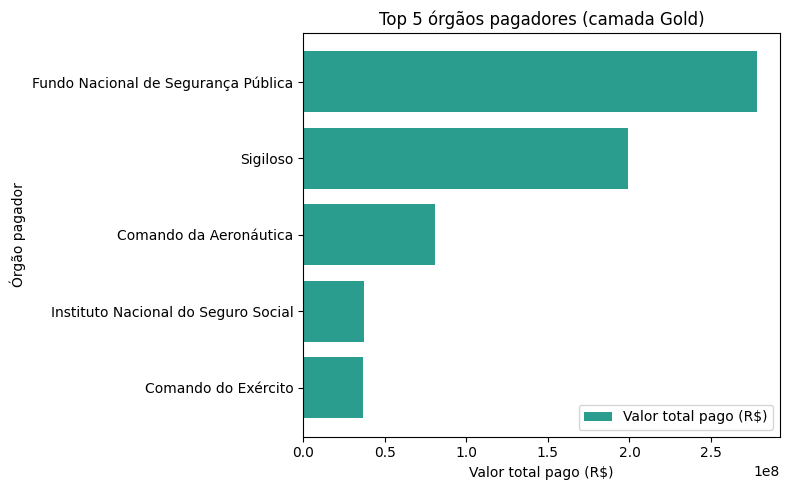

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_pagadores["nome_orgao_pagador"], top_pagadores["valor_total_pago"], color="#2A9D8F", label="Valor total pago (R$)")
ax.set_xlabel("Valor total pago (R$)")
ax.set_ylabel("Órgão pagador")
ax.set_title("Top 5 órgãos pagadores (camada Gold)")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()

### 5. Qual o tipo de pagamento com maior valor médio?

Consulta a view Gold `vw_gold_pagamento_por_tipo`.

In [11]:
sql_tipo_pagamento = """
SELECT tipo_pagamento, valor_medio, qtd
FROM vw_gold_pagamento_por_tipo
ORDER BY valor_medio DESC;
"""
tipo_pagamento = pd.read_sql(sql_tipo_pagamento, conexao)
tipo_pagamento

C:\Users\luana\AppData\Local\Temp\ipykernel_23624\4230202373.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  tipo_pagamento = pd.read_sql(sql_tipo_pagamento, conexao)


,tipo_pagamento,valor_medio,qtd
0,DIÁRIAS,"2,078.79",400364
1,PASSAGEM,"1,882.32",182883
2,Serviço correlato: seguro,447.26,4789
3,RESTITUIÇÃO,245.70,11574


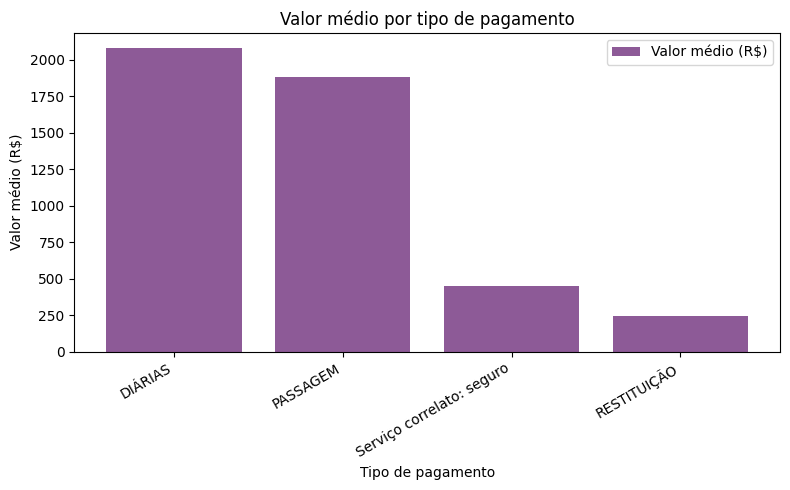

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(tipo_pagamento["tipo_pagamento"], tipo_pagamento["valor_medio"], color="#8D5A97", label="Valor médio (R$)")
ax.set_xlabel("Tipo de pagamento")
ax.set_ylabel("Valor médio (R$)")
ax.set_title("Valor médio por tipo de pagamento")
plt.xticks(rotation=30, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

### 6. Qual o meio de transporte mais usado nos trechos?

Consulta a view Gold `vw_gold_trecho_por_transporte`.

In [13]:
sql_meio_transporte = """
SELECT meio_transporte, qtd_trechos
FROM vw_gold_trecho_por_transporte
ORDER BY qtd_trechos DESC;
"""
meio_transporte = pd.read_sql(sql_meio_transporte, conexao)
meio_transporte

C:\Users\luana\AppData\Local\Temp\ipykernel_23624\2009169758.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  meio_transporte = pd.read_sql(sql_meio_transporte, conexao)


,meio_transporte,qtd_trechos
0,Veículo Oficial,385734
1,Aéreo,226707
2,Rodoviário,64454
3,Veículo Próprio,42736
4,Inválido,26523
5,Fluvial,8392
6,Ferroviário,868
7,Marítimo,471


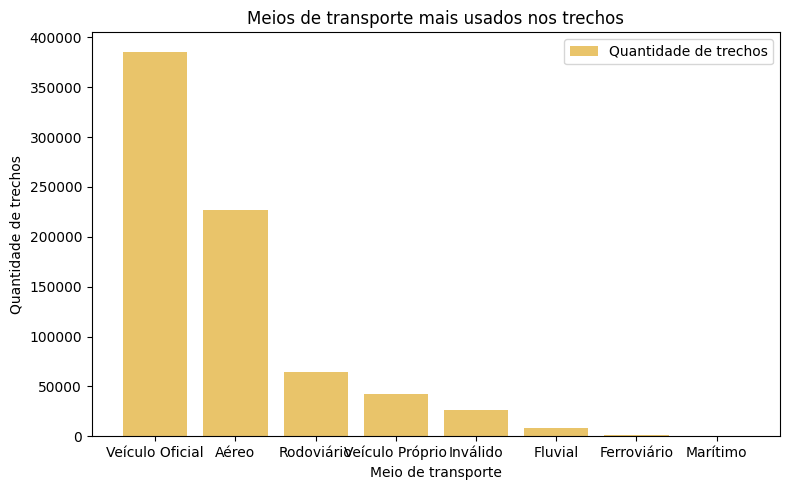

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(meio_transporte["meio_transporte"], meio_transporte["qtd_trechos"], color="#E9C46A", label="Quantidade de trechos")
ax.set_xlabel("Meio de transporte")
ax.set_ylabel("Quantidade de trechos")
ax.set_title("Meios de transporte mais usados nos trechos")
ax.legend()
plt.tight_layout()
plt.show()

### 7. Qual UF de destino aparece em mais trechos?

Consulta a view Gold `vw_gold_trecho_por_uf`.

In [15]:
sql_uf_destino = """
SELECT destino_uf, qtd_trechos
FROM vw_gold_trecho_por_uf
ORDER BY qtd_trechos DESC
LIMIT 10;
"""
uf_destino = pd.read_sql(sql_uf_destino, conexao)
uf_destino

C:\Users\luana\AppData\Local\Temp\ipykernel_23624\396521460.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  uf_destino = pd.read_sql(sql_uf_destino, conexao)


,destino_uf,qtd_trechos
0,São Paulo,81727
1,Distrito Federal,77962
2,Minas Gerais,50555
3,Rio de Janeiro,43481
4,Paraná,42323
5,Pará,39742
6,Rio Grande do Sul,38397
7,Mato Grosso do Sul,30450
8,Bahia,28141
9,Pernambuco,28117


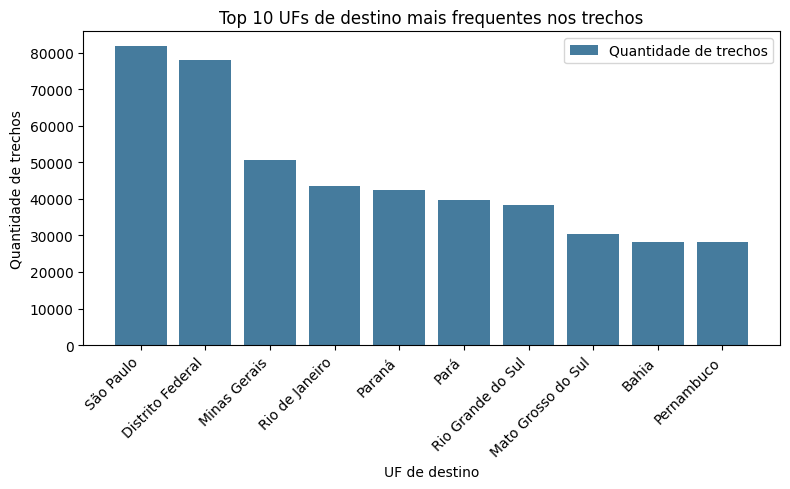

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(uf_destino["destino_uf"], uf_destino["qtd_trechos"], color="#457B9D", label="Quantidade de trechos")
ax.set_xlabel("UF de destino")
ax.set_ylabel("Quantidade de trechos")
ax.set_title("Top 10 UFs de destino mais frequentes nos trechos")
plt.xticks(rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

## Conclusões e insights

* **Concentração de gastos**: o Ministério da Justiça e Segurança Pública
  lidera com folga o custo total de viagens (~R$ 487 milhões), quase o
  triplo do segundo colocado (Ministério da Defesa, ~R$ 156 milhões). Os 5
  maiores órgãos somam 71,1% do custo total do período.
* **Órgão superior vs. órgão pagador são granularidades diferentes**: por
  `nome_orgao_superior` (pergunta 1), o Ministério da Justiça e Segurança
  Pública lidera o custo total de viagens. Já por `nome_orgao_pagador`
  (pergunta 4, a partir de `silver_pagamento` filtrado para viagens
  realizadas), quem mais pagou é o Fundo Nacional de Segurança Pública
  (~R$ 278,3 milhões), uma unidade vinculada a esse mesmo ministério, o que
  é coerente, mas não é a mesma coisa: `nome_orgao_pagador` identifica a
  unidade que efetivamente processou o pagamento, não o órgão superior ao
  qual a viagem está ligada. Vale notar também que "Sigiloso" aparece como
  o 2º maior pagador (~R$ 199,3 milhões), sinal de que uma parcela
  relevante dos pagamentos tem o órgão pagador classificado como
  confidencial, o que limita a análise por órgão nesses casos.
* **Diárias, não passagens, dominam o gasto médio**: o tipo de pagamento com
  maior valor médio é "Diárias" (R$ 2.078,79), à frente de "Passagem"
  (R$ 1.882,32), sinal de que viagens longas pesam mais no orçamento do que
  o deslocamento em si.
* **Veículo oficial é o meio mais usado**: 385.734 trechos em viagens
  realizadas (bem à frente do meio aéreo, com 226.707), mostrando que a
  maior parte da movimentação é terrestre e de curta distância dentro do
  próprio território, não viagens aéreas de longo curso.
* **Concentração geográfica em poucos estados**: São Paulo, Distrito Federal
  e Minas Gerais concentram a maior quantidade de trechos com destino,
  coerente com a presença de órgãos federais em Brasília e dos grandes
  polos econômicos do Sudeste.
* **Destino final (não trecho) revela custos de cidades remotas e
  internacionais**: usando a última cidade de `destinos` em `silver_viagem`
  como destino final da viagem (pergunta 2), os maiores custos médios são de
  Amarante do Maranhão/MA, Nonoai/RS e Xangai/China, cidades pequenas/remotas
  ou internacionais, coerente com viagens raras que exigem deslocamento caro
  (passagens + muitas diárias) para chegar a localidades distantes dos
  grandes polos, ou voos internacionais.
* **Outlier de longa duração**: a viagem mais longa do período durou 384
  dias (quase 13 meses), mas está registrada com `valor_total = R$ 0,00`,
  um indício de que o custeio dessa viagem específica (provavelmente um
  afastamento de longa duração) não passou pelos campos de diárias/passagens
  do PCDP, o que é um ponto de atenção para quem for auditar os dados na
  origem.

In [17]:
conexao.close()